In [4]:
!pip install pywifi
!pip install comtypes

In [5]:
import pywifi
from pywifi import const
import time

def scan_networks():
    wifi = pywifi.PyWiFi()
    iface = wifi.interfaces()[0]  # get the first wireless interface
    iface.scan()  # start scanning
    time.sleep(3)  # wait for the scan to complete
    
    scan_results = iface.scan_results()
    
    networks = []
    for network in scan_results:
        networks.append({
            'SSID': network.ssid,
            'Signal': network.signal,
            'BSSID': network.bssid,
            'Channel': network.freq
        })
    
    return networks

def display_networks(networks):
    print("Available Wi-Fi Networks:")
    print("SSID".ljust(30), "Signal Strength".ljust(15), "BSSID".ljust(20), "Channel")
    print("-" * 75)
    
    for network in networks:
        print(f"{network['SSID'].ljust(30)} {str(network['Signal']).ljust(15)} {network['BSSID'].ljust(20)} {network['Channel']}")

if __name__ == "__main__":
    networks = scan_networks()
    display_networks(networks)


Available Wi-Fi Networks:
SSID                           Signal Strength BSSID                Channel
---------------------------------------------------------------------------
air_network                    -72             10:27:f5:01:e5:9f:   5200000
air_network                    -19             10:27:f5:01:ed:7b:   5200000
air_network                    -71             10:27:f5:01:d5:5b:   5200000
air_network                    -62             10:27:f5:01:d5:5a:   2452000
air_network                    -65             10:27:f5:01:e5:9e:   2452000
air_network                    -19             10:27:f5:01:ed:7a:   2452000
                               -61             16:27:f5:01:d5:5a:   2452000
                               -71             16:27:f5:01:e5:9f:   5200000
                               -17             16:27:f5:01:ed:7a:   2452000
TelstraDA8409                  -83             a2:b5:3c:da:84:11:   2437000
TelstraBC0B3B                  -83             20:b0:01:bc:0b:

Available Wi-Fi Networks:
SSID                           Signal Strength BSSID                Channel
---------------------------------------------------------------------------
air_network                    -71             10:27:f5:01:e5:9f:   5200000
air_network                    -15             10:27:f5:01:ed:7b:   5200000
air_network                    -76             10:27:f5:01:d5:5b:   5200000
air_network                    -62             10:27:f5:01:d5:5a:   2452000
air_network                    -64             10:27:f5:01:e5:9e:   2452000
air_network                    -15             10:27:f5:01:ed:7a:   2452000
                               -64             16:27:f5:01:e5:9e:   2452000
                               -61             16:27:f5:01:d5:5a:   2452000
                               -71             16:27:f5:01:e5:9f:   5200000
                               -17             16:27:f5:01:ed:7a:   2452000
TelstraDA8409                  -83             a2:b5:3c:da:84:

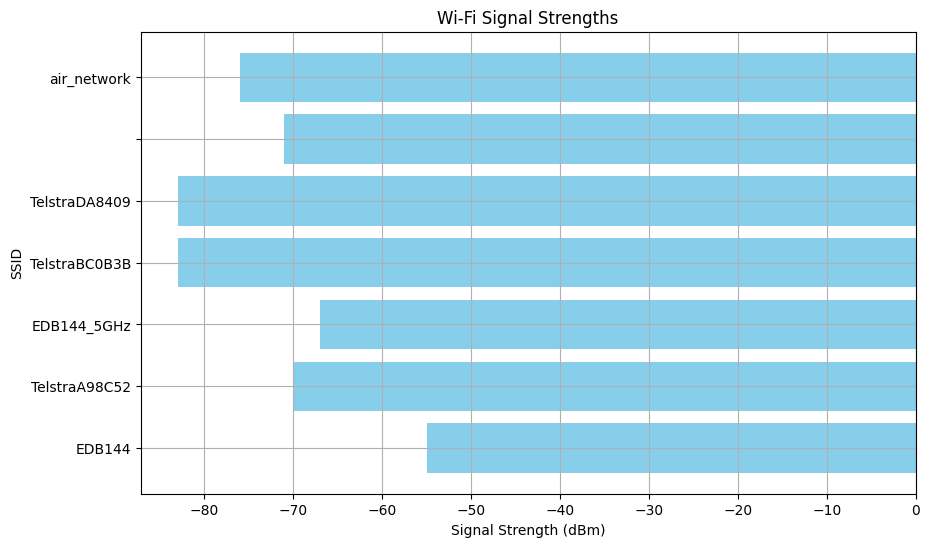

In [6]:
import pywifi
from pywifi import const
import time
import matplotlib.pyplot as plt

def scan_networks():
    wifi = pywifi.PyWiFi()
    iface = wifi.interfaces()[0]  # get the first wireless interface
    iface.scan()  # start scanning
    time.sleep(3)  # wait for the scan to complete
    
    scan_results = iface.scan_results()
    
    networks = []
    for network in scan_results:
        networks.append({
            'SSID': network.ssid,
            'Signal': network.signal,
            'BSSID': network.bssid,
            'Channel': network.freq
        })
    
    return networks

def display_networks(networks):
    print("Available Wi-Fi Networks:")
    print("SSID".ljust(30), "Signal Strength".ljust(15), "BSSID".ljust(20), "Channel")
    print("-" * 75)
    
    for network in networks:
        print(f"{network['SSID'].ljust(30)} {str(network['Signal']).ljust(15)} {network['BSSID'].ljust(20)} {network['Channel']}")

def plot_networks(networks):
    ssids = [network['SSID'] for network in networks]
    signals = [network['Signal'] for network in networks]
    
    plt.figure(figsize=(10, 6))
    plt.barh(ssids, signals, color='skyblue')
    plt.xlabel('Signal Strength (dBm)')
    plt.ylabel('SSID')
    plt.title('Wi-Fi Signal Strengths')
    plt.gca().invert_yaxis()  # Invert y-axis to have strongest signals on top
    plt.grid(True)
    plt.show()

if __name__ == "__main__":
    networks = scan_networks()
    display_networks(networks)
    plot_networks(networks)


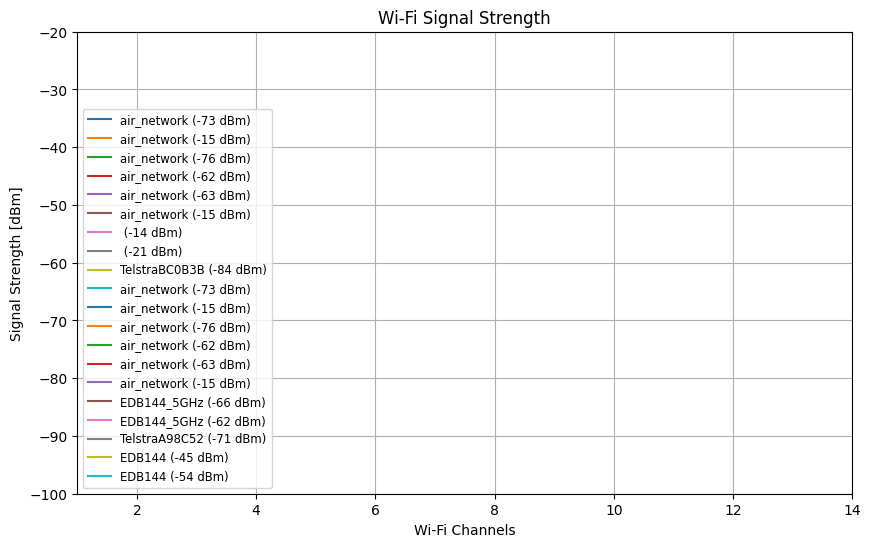

In [13]:
import pywifi
import time
import numpy as np
import matplotlib.pyplot as plt

def scan_networks():
    wifi = pywifi.PyWiFi()
    iface = wifi.interfaces()[0]  # get the first wireless interface
    iface.scan()  # start scanning
    time.sleep(3)  # wait for the scan to complete
    
    scan_results = iface.scan_results()
    
    networks = []
    for network in scan_results:
        networks.append({
            'SSID': network.ssid,
            'Signal': network.signal,
            'BSSID': network.bssid,
            'Channel': int((network.freq - 2412) / 5 + 1)  # Convert frequency to channel number
        })
    
    return networks

def plot_wifi_signals(networks):
    plt.figure(figsize=(10, 6))
    
    for network in networks:
        signal_strength = network['Signal']
        channel = network['Channel']
        ssid = network['SSID']
        
        # Generate a Gaussian curve centered at the channel
        x = np.linspace(1, 14, 400)  # Wi-Fi channels 1 to 14
        y = (signal_strength + 100) * np.exp(-0.5 * ((x - channel) / 1.5) ** 2)  # Increase height and width
        
        plt.plot(x, y, label=f"{ssid} ({signal_strength} dBm)")
    
    plt.title("Wi-Fi Signal Strength")
    plt.xlabel("Wi-Fi Channels")
    plt.ylabel("Signal Strength [dBm]")
    plt.ylim(-100, -20)
    plt.xlim(1, 14)
    plt.grid(True)
    plt.legend(loc='lower left', fontsize='small')
    plt.show()

if __name__ == "__main__":
    networks = scan_networks()
    plot_wifi_signals(networks)


In [12]:
import pywifi

def list_interfaces():
    wifi = pywifi.PyWiFi()
    interfaces = wifi.interfaces()
    for i, iface in enumerate(interfaces):
        print(f"Interface {i}: {iface.name()}")

if __name__ == "__main__":
    list_interfaces()


Interface 0: Intel(R) Wi-Fi 6E AX211 160MHz


In [15]:
pip install scapy

     ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
     -------------------------------- ------- 1.0/1.3 MB 5.6 MB/s eta 0:00:01
     ---------------------------------------- 1.3/1.3 MB 5.9 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for scapy: filename=scapy-2.5.0-py2.py3-none-any.whl size=1444339 sha256=604625182dfaf30cb415bfafde4db9a983b3f5253d3cadd57a786c80f9c9d613
  Stored in directory: c:\users\ilo_l\appdata\local\pip\cache\wheels\8a\5e\7c\6f92df559dadf49d0e31cecdd5b104fc8c38a7c67fde16b029
Successfully built scapy
Note: you may need to restart the kernel to use updated packages.


In [19]:
from scapy.all import *
from scapy.layers.dot11 import Dot11, Dot11Beacon, Dot11ProbeResp

def wifi_scan():
    def packet_handler(packet):
        if packet.haslayer(Dot11Beacon) or packet.haslayer(Dot11ProbeResp):
            ssid = packet[Dot11Elt].info.decode() if packet[Dot11Elt].info else 'Hidden SSID'
            bssid = packet[Dot11].addr2
            dbm_signal = packet.dBm_AntSignal
            channel = int(ord(packet[Dot11Elt:3].info))
            
            if bssid not in networks:
                networks[bssid] = (ssid, dbm_signal, channel)
                print(f"SSID: {ssid}, BSSID: {bssid}, Signal: {dbm_signal} dBm, Channel: {channel}")

    networks = {}
    
    print("Starting Wi-Fi scan...")
    # You may need to change 'wlan0' to the correct network interface on your machine
    sniff(prn=packet_handler, iface='Wi-Fi', timeout=30)  # Sniff for 30 seconds

if __name__ == "__main__":
    wifi_scan()


Starting Wi-Fi scan...
